# LSTM Architecture & Point Forecasting Experiments
This notebook explores different architectures and configurations for the LSTM to improve point forecasting accuracy. Specifically, we evaluate different architectures (e.g. standard vs bidirectional LSTM) and dedicate a separate model specifically trained and optimized for 1-step forecasting, as relying on the first step of a 12-step trained model is suboptimal and yields structural inaccuracies.

In [ ]:
# Run from repo root so that data/ and src/ resolve
import os, sys
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.insert(0, os.getcwd())

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

# Load data
df = pd.read_csv('data/augmented_data.csv')
series = df[df['secteur'] == df['secteur'].iloc[0]]['trafic_mbps'].values
print(f"Data shape: {series.shape}")

Data shape: (1335,)


In [2]:
# Data preparation function
def create_sequences(data, seq_length, pred_length):
    xs, ys = [], []
    for i in range(len(data) - seq_length - pred_length + 1):
        x = data[i:(i + seq_length)]
        y = data[(i + seq_length):(i + seq_length + pred_length)]
        xs.append(x)
        ys.append(y)
    return np.array(xs), np.array(ys)

scaler = MinMaxScaler(feature_range=(-1, 1))
scaled_series = scaler.fit_transform(series.reshape(-1, 1)).flatten()

# Train/Val/Test split on the scaled data
train_size = int(len(scaled_series) * 0.7)
val_size = int(len(scaled_series) * 0.15)
train_data = scaled_series[:train_size]
val_data = scaled_series[train_size:train_size+val_size]
test_data = scaled_series[train_size+val_size:]

In [3]:
# Model Definitions
class PointLSTM(nn.Module):
    def __init__(self, hidden_layer_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_layer_size, num_layers, batch_first=True, dropout=0.2)
        self.linear = nn.Linear(hidden_layer_size, 1) # Predict exactly 1 step ahead
    def forward(self, input_seq):
        lstm_out, _ = self.lstm(input_seq)
        return self.linear(lstm_out[:, -1, :])

class PointBiLSTM(nn.Module):
    def __init__(self, hidden_layer_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_layer_size, num_layers, batch_first=True, dropout=0.2, bidirectional=True)
        self.linear = nn.Linear(hidden_layer_size * 2, 1)
    def forward(self, input_seq):
        lstm_out, _ = self.lstm(input_seq)
        return self.linear(lstm_out[:, -1, :])

class DeepPointLSTM(nn.Module):
    def __init__(self, hidden_layer_size=128, num_layers=4):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_layer_size, num_layers, batch_first=True, dropout=0.3)
        self.linear = nn.Linear(hidden_layer_size, 1)
    def forward(self, input_seq):
        lstm_out, _ = self.lstm(input_seq)
        return self.linear(lstm_out[:, -1, :])

In [4]:
# Training Loop
def train_model(model, train_loader, val_loader, epochs=50, lr=0.001, patience=5):
    device = "cpu"
    model.to(device)
    loss_function = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    
    best_val_loss = float("inf")
    early_stop_counter = 0
    best_model_state = None
    
    for i in range(epochs):
        model.train()
        for seq, labels in train_loader:
            seq, labels = seq.to(device), labels.to(device)
            optimizer.zero_grad()
            y_pred = model(seq)
            loss = loss_function(y_pred, labels.squeeze(-1))
            loss.backward()
            optimizer.step()
            
        model.eval()
        val_loss = 0
        with torch.no_grad():
            for seq, labels in val_loader:
                seq, labels = seq.to(device), labels.to(device)
                y_pred = model(seq)
                val_loss += loss_function(y_pred, labels.squeeze(-1)).item()
        val_loss /= len(val_loader)
        
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = model.state_dict()
            early_stop_counter = 0
        else:
            early_stop_counter += 1
            if early_stop_counter >= patience:
                break
                
    model.load_state_dict(best_model_state)
    return model


In [5]:
# Evaluate Architectures on 1-Step Forecasting
seq_length = 60
pred_length = 1

X_train, y_train = create_sequences(train_data, seq_length, pred_length)
X_val, y_val = create_sequences(val_data, seq_length, pred_length)
X_test, y_test = create_sequences(test_data, seq_length, pred_length)

def to_loader(X, y):
    return DataLoader(TensorDataset(torch.tensor(X, dtype=torch.float32).unsqueeze(-1), torch.tensor(y, dtype=torch.float32).unsqueeze(-1)), batch_size=32, shuffle=True)

train_loader = to_loader(X_train, y_train)
val_loader = to_loader(X_val, y_val)
test_loader = to_loader(X_test, y_test)

models = {
    "Standard LSTM": PointLSTM(),
    "Bidirectional LSTM": PointBiLSTM(),
    "Deep LSTM": DeepPointLSTM()
}

results = {}
for name, m in models.items():
    print(f"Training {name}...")
    m = train_model(m, train_loader, val_loader)
    
    m.eval()
    preds = []
    with torch.no_grad():
        for seq, _ in test_loader:
            preds.append(m(seq).numpy())
    preds = np.concatenate(preds).flatten()
    
    # Inverse transform
    preds_inv = scaler.inverse_transform(preds.reshape(-1, 1)).flatten()
    actuals_inv = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()
    
    rmse = np.sqrt(mean_squared_error(actuals_inv, preds_inv))
    results[name] = {"rmse": rmse, "preds": preds_inv}
    print(f"{name} RMSE (1-step): {rmse:.2f}")


Training Standard LSTM...


Standard LSTM RMSE (1-step): 10.46
Training Bidirectional LSTM...


Bidirectional LSTM RMSE (1-step): 10.51
Training Deep LSTM...


Deep LSTM RMSE (1-step): 10.52


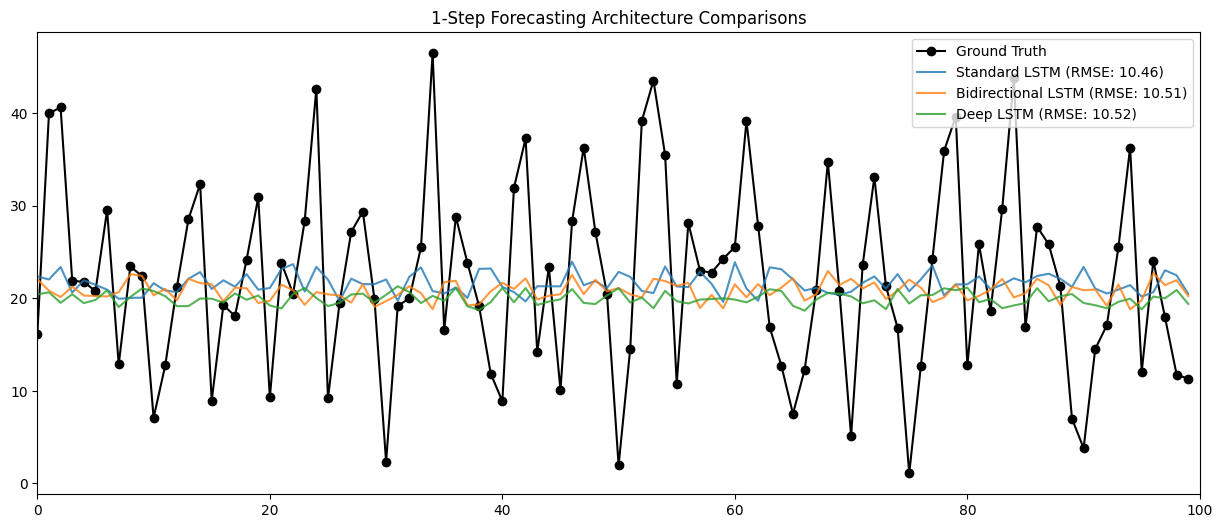

In [6]:
# Plotting
plt.figure(figsize=(15, 6))
plt.plot(actuals_inv[-100:], label="Ground Truth", color="black", marker='o')
for name, res in results.items():
    plt.plot(res["preds"][-100:], label=f"{name} (RMSE: {res['rmse']:.2f})", alpha=0.8)
plt.legend()
plt.title("1-Step Forecasting Architecture Comparisons")
plt.xlim(0, 100)
plt.show()
